In [90]:
import stumpy as stumpy
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

In [93]:
df_orig = pd.read_csv("datasets/Mobai/jul_aug_sep_oct_2022_msc_1.csv", sep=";")
df_orig["TIMESTAMP"] = pd.to_datetime(df_orig["Start Date"], format="%d/%m/%Y") + pd.to_timedelta(df_orig["Start Hour"], unit='h')
df_orig.dropna(0, inplace=True)
df_orig["#Events"] = df_orig["#Events"].str.replace(' ', '').astype(int)
df_orig

/home/emanuel/miniconda3/envs/pony2/lib/python3.7/site-packages/ipykernel_launcher.py:3: FutureWarning: In a future version of pandas all arguments of DataFrame.dropna will be keyword-only
  This is separate from the ipykernel package so we can avoid doing imports until


,Datasource,Start Date,Start Hour,Call Type,Event Type,Subscriber Type,Traffic Type,Service Type,Partner Description,#Events,Event Duration,TIMESTAMP
0,MSC_OUT_NOK,18/07/2022,0,SMS,ORIGINATED,Postpaid,OFF-NET,NOT-ROAMING,P_0001,105,0,2022-07-18 00:00:00
1,MSC_OUT_NOK,18/07/2022,0,VOICE,CALL FORWARD,Application,INT,NOT-ROAMING,P_0001,16,2189,2022-07-18 00:00:00
2,MSC_OUT_NOK,18/07/2022,0,VOICE,TERMINATED,Roamer In,INT,NOT-ROAMING,P_0002,7,1683,2022-07-18 00:00:00
3,MSC_OUT_NOK,18/07/2022,0,VOICE,TERMINATED,Roamer In,INT,NOT-ROAMING,P_0003,15,1695,2022-07-18 00:00:00
4,MSC_OUT_NOK,18/07/2022,0,VOICE,TERMINATED,Roamer In,INT,NOT-ROAMING,P_0004,1,41,2022-07-18 00:00:00
...,...,...,...,...,...,...,...,...,...,...,...,...
958783,MSC_OUT_NOK,13/10/2022,21,SMS,TERMINATED,Roamer In,INT,NOT-ROAMING,P_0280,30,0,2022-10-13 21:00:00
958784,MSC_OUT_NOK,13/10/2022,21,SMS,TERMINATED,Roamer In,INT,NOT-ROAMING,P_0079,265,0,2022-10-13 21:00:00
958785,MSC_OUT_NOK,13/10/2022,21,SMS,TERMINATED,Roamer In,INT,NOT-ROAMING,P_0102,6,0,2022-10-13 21:00:00
958786,MSC_OUT_NOK,13/10/2022,21,SMS,TERMINATED,Roamer In,INT,NOT-ROAMING,P_0022,3,0,2022-10-13 21:00:00


In [92]:
df = pd.read_csv("datasets/Mobai/df_anomaly.csv")
df

,Call Type,Event Type,Subscriber Type,Traffic Type,Service Type,Partner Description,#Events,TIMESTAMP,Anomaly
0,SMS,ORIGINATED,Postpaid,OFF-NET,NOT-ROAMING,P_0001,105,2022-07-18 00:00:00,0
1,VOICE,CALL FORWARD,Application,INT,NOT-ROAMING,P_0001,16,2022-07-18 00:00:00,0
2,VOICE,TERMINATED,Roamer In,INT,NOT-ROAMING,P_0002,7,2022-07-18 00:00:00,0
3,VOICE,TERMINATED,Roamer In,INT,NOT-ROAMING,P_0003,15,2022-07-18 00:00:00,0
4,VOICE,TERMINATED,Roamer In,INT,NOT-ROAMING,P_0004,1,2022-07-18 00:00:00,0
...,...,...,...,...,...,...,...,...,...
958475,SMS,TERMINATED,Roamer In,INT,NOT-ROAMING,P_0280,30,2022-10-13 21:00:00,0
958476,SMS,TERMINATED,Roamer In,INT,NOT-ROAMING,P_0079,265,2022-10-13 21:00:00,0
958477,SMS,TERMINATED,Roamer In,INT,NOT-ROAMING,P_0102,6,2022-10-13 21:00:00,0
958478,SMS,TERMINATED,Roamer In,INT,NOT-ROAMING,P_0022,3,2022-10-13 21:00:00,0


In [94]:
def filter_aggregate(df, cats, vals):
    for i, cat in enumerate(cats):
        df = df[df[cat] == vals[i]]
    df = df.groupby(["TIMESTAMP"]).agg("sum").reset_index()
    return df

In [98]:
cats = ["Call Type", "Traffic Type"]
vals = ["VOICE", "INT"]
df_agg = filter_aggregate(df, cats, vals)
df_orig_agg = filter_aggregate(df_orig, cats, vals)

In [99]:
mp = stumpy.stump(df_agg['#Events'].astype(float), m=168, ignore_trivial=True)

In [100]:
datetimes = pd.to_datetime(df_agg['TIMESTAMP'])

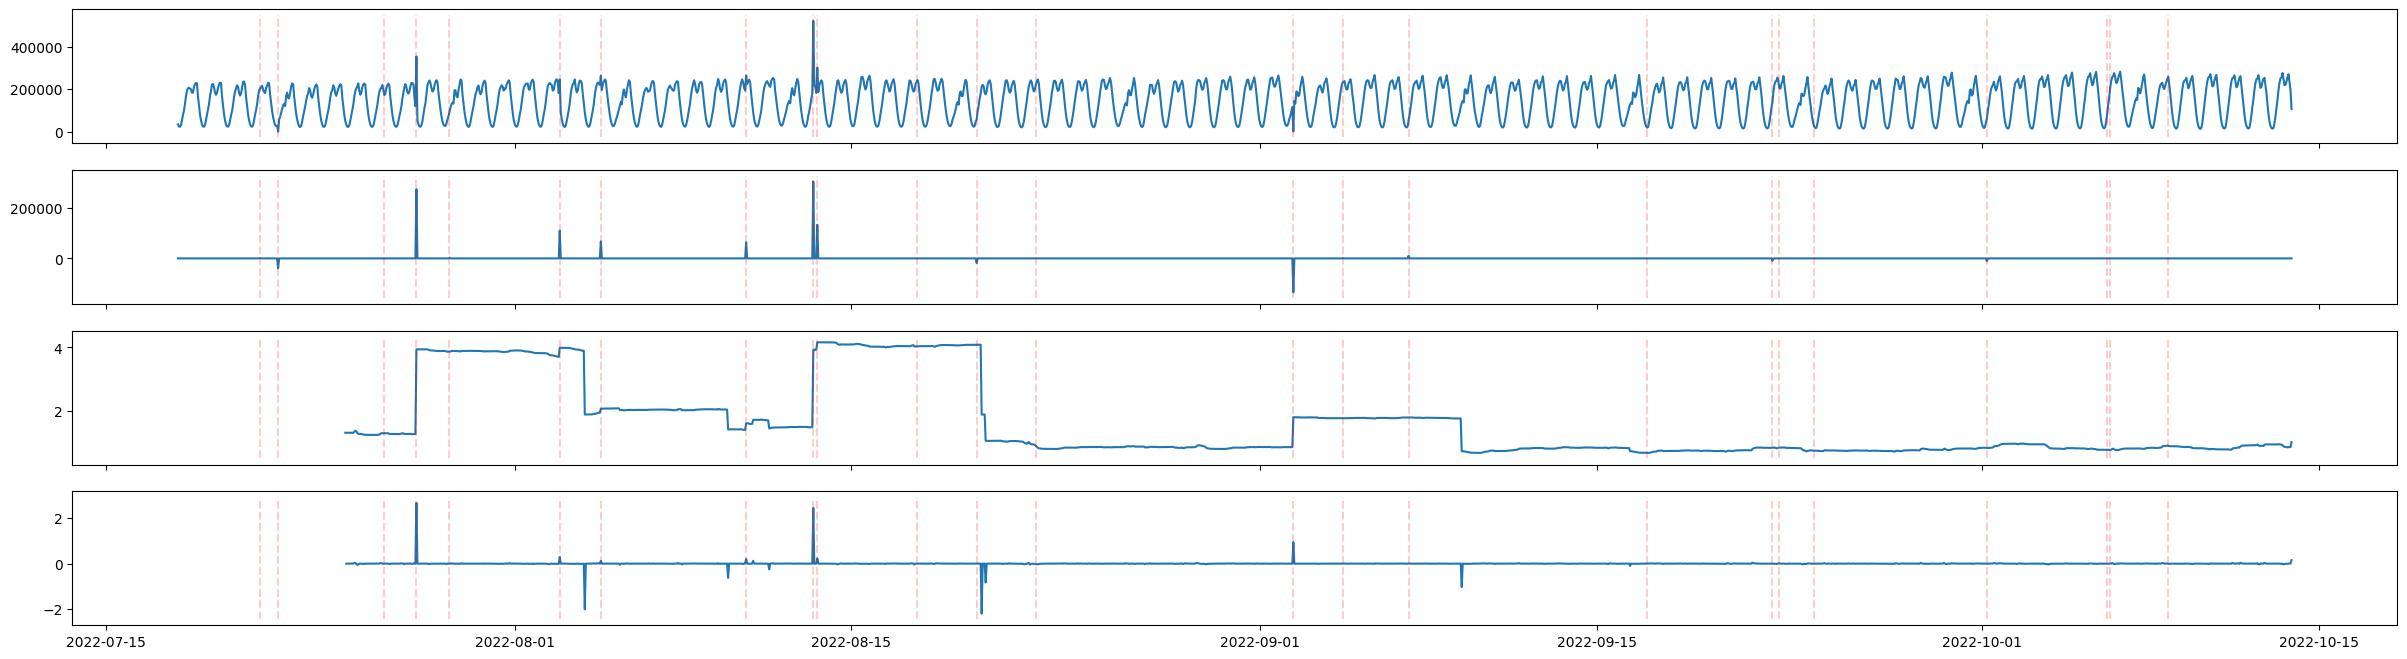

In [123]:
f, axs = plt.subplots(4,1, figsize=(30,8), sharex=True)
axs[0].plot(datetimes, df_agg['#Events'])
axs[1].plot(datetimes, df_agg['#Events']-df_orig_agg['#Events'])
axs[2].plot(datetimes[167:], mp[:,0])
axs[3].plot(datetimes[168:], np.diff(mp[:,0]))
for ax in axs:
    ymin, ymax = ax.get_ylim()
    ax.vlines(datetimes[df_agg[df_agg['Anomaly']!=0].index], ymin=ymin, ymax=ymax, color='r', linestyle='--', label='Anomaly', alpha=0.2)